# Binary Logistic Regression

## Will the delivery be late?

A longer preparation wait leaves less time to meet a delivery promise. In this synthetic dataset, late means arriving after 40 minutes. The input is preparation wait in minutes; the observed label is late or on time.

Logistic regression combines an intercept and a weighted input into a score. The sigmoid function converts that score to a probability between zero and one. Despite its name, logistic regression is used for classification.

> Preparation wait → linear score → sigmoid → probability of being late

<img src="https://raw.githubusercontent.com/sonamu-jun/introduction-to-ai-convergence/main/07-1_Classification/assets/02_sigmoid_and_threshold.png" alt="The fitted sigmoid links preparation wait to late probability. The horizontal threshold determines the predicted class of a new delivery." width="640" style="max-width:100%;height:auto;">

The intercept shifts the score. The coefficient changes how strongly waiting time affects it. Fitting adjusts both values. A threshold turns the probability into a class: at or above the threshold, the prediction is late.


## Fitting probabilities and choosing a threshold

Binary cross-entropy, also called log loss, penalizes a model for assigning low probability to the observed class. A confidently wrong prediction receives a large penalty. Gradient descent adjusts the coefficients in the direction that reduces this training loss; the learning rate sets the size of each update.

The iteration control selects coefficients from actual gradient descent updates. `Fit model` applies the final update. The preparation-wait control changes the new delivery, and the orange point follows the same probability curve used for classification.

The dashed line is the threshold. Lowering it flags more deliveries as late without changing the curve or its training loss. Filled points show observed training labels at zero or one. Validation accuracy uses separate deliveries that never update the coefficients.


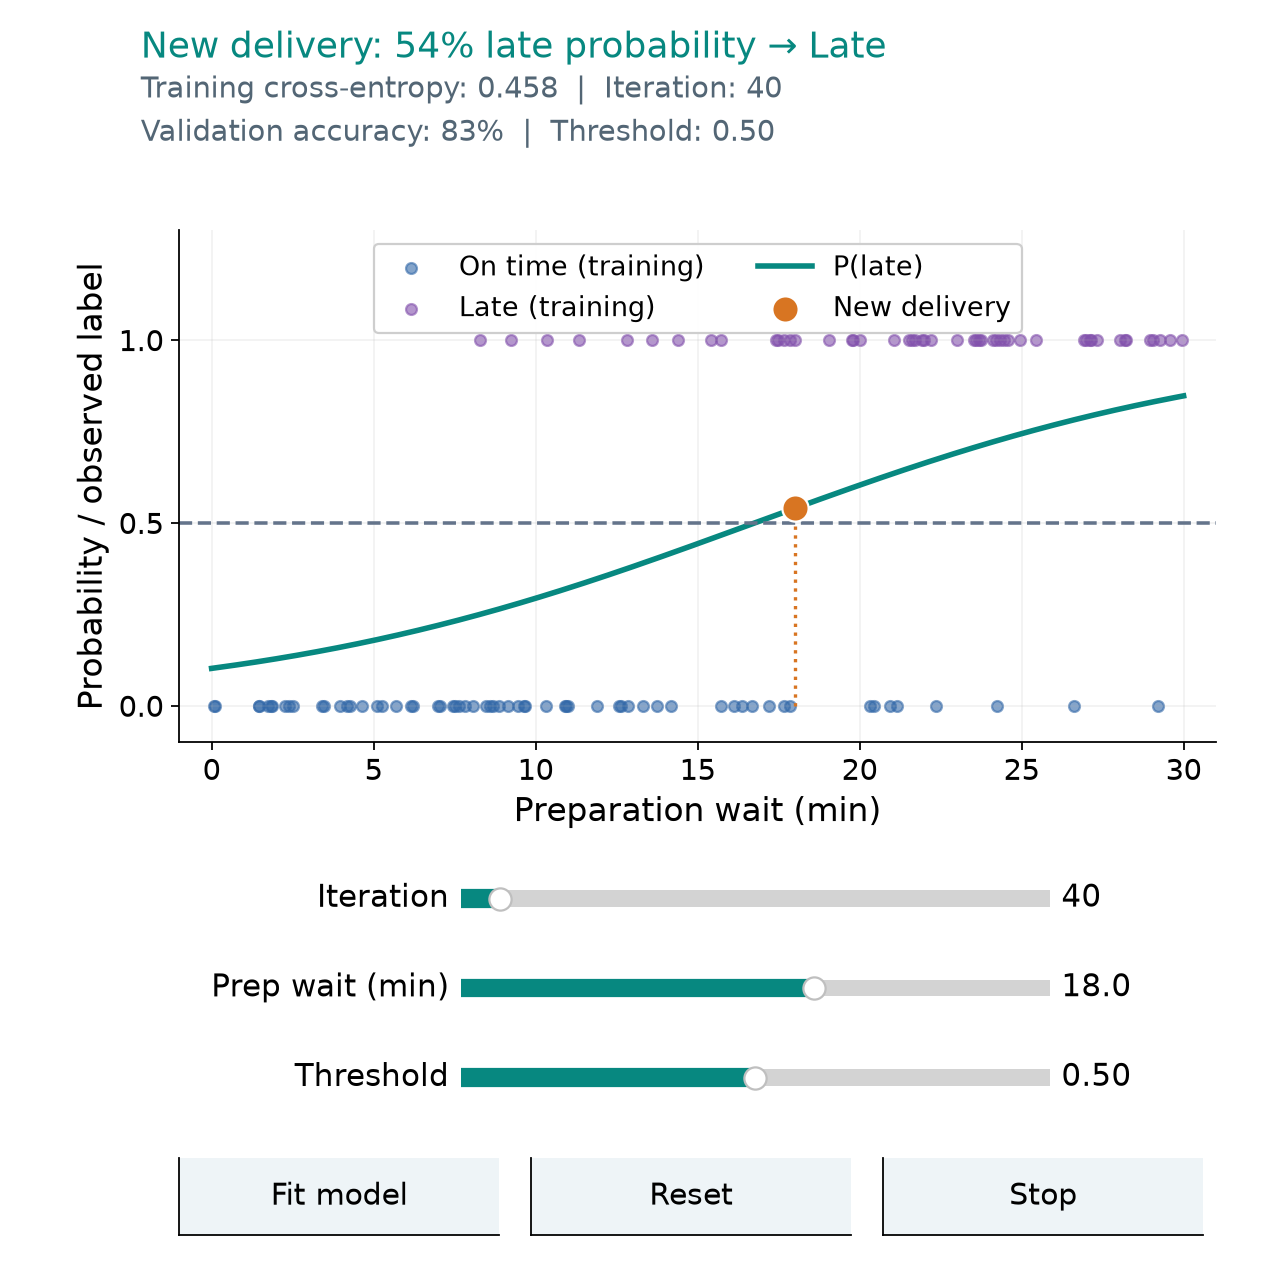

In [1]:
import os
import sys
import io
import numpy as np
import matplotlib

CLASSIFICATION_STATIC = os.environ.get("CLASSIFICATION_STATIC") == "1"
CLASSIFICATION_BROWSER = sys.platform == "emscripten"
if not CLASSIFICATION_STATIC and not CLASSIFICATION_BROWSER:
    from IPython import get_ipython
    shell = get_ipython()
    if shell is not None and getattr(shell, "kernel", None) is not None:
        shell.run_line_magic("matplotlib", "widget")

import matplotlib.pyplot as plt
from matplotlib.widgets import Slider, Button
from matplotlib.colors import ListedColormap
from IPython.display import Image, display
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

plt.rcParams.update({
    "font.size": 15, "axes.labelsize": 15,
    "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .16, "lines.linewidth": 2.5,
    "axes.unicode_minus": False, "figure.facecolor": "white",
})
BLUE, TEAL, ORANGE, PURPLE = "#3268a8", "#078880", "#d87522", "#8251ac"


def sigmoid(score):
    score = np.clip(np.asarray(score, dtype=float), -500, 500)
    return 1 / (1 + np.exp(-score))


def softmax(scores):
    scores = np.asarray(scores, dtype=float)
    weights = np.exp(scores - scores.max(axis=-1, keepdims=True))
    return weights / weights.sum(axis=-1, keepdims=True)


def binary_loss(labels, scores):
    # The logaddexp form avoids taking log(0) at extreme scores.
    return float(np.mean(np.logaddexp(0, scores) - labels * scores))


def classification_metrics(observed, predicted):
    observed, predicted = np.asarray(observed), np.asarray(predicted)
    tp = int(np.sum((observed == 1) & (predicted == 1)))
    tn = int(np.sum((observed == 0) & (predicted == 0)))
    fp = int(np.sum((observed == 0) & (predicted == 1)))
    fn = int(np.sum((observed == 1) & (predicted == 0)))
    return {"TP": tp, "TN": tn, "FP": fp, "FN": fn,
            "accuracy": (tp + tn) / len(observed),
            "precision": tp / (tp + fp) if tp + fp else np.nan,
            "recall": tp / (tp + fn) if tp + fn else np.nan,
            "F1": 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else np.nan}


def percent(value):
    return "undefined" if not np.isfinite(value) else f"{value:.0%}"


# A rerun releases the previous figure and its input callbacks first.
for _previous_view in globals().get("_classification_views", {}).values():
    _previous_view.close()
_classification_views = {}


class ClassificationExplorer:
    """One figure keeps the selected model, predictions and scores together."""

    def __init__(self, name, render, sliders, actions=()):
        self.render = render
        self.slider_specs = sliders
        self.controls, self.buttons, self.state = {}, {}, {}
        self.stopped = False
        self.defaults = {key: initial for key, label, low, high, initial, step, fmt in sliders}
        with plt.ioff():
            self.figure = plt.figure(figsize=(8, 8.0 if len(sliders) == 3 else 7.4), dpi=80)
        self.status = self.figure.text(.11, .955, "", fontsize=16, color=TEAL)
        self.detail = self.figure.text(.11, .89, "", fontsize=13, color="#536675", linespacing=1.5)
        bottom = .28 + .07 * (len(sliders) - 1)
        self.ax = self.figure.add_axes([.14, bottom, .81, .82 - bottom])
        for i, (key, label, low, high, initial, step, fmt) in enumerate(sliders):
            y = .145 + .07 * (len(sliders) - i - 1)
            slider = Slider(self.figure.add_axes([.36, y, .46, .026]),
                            label, low, high, valinit=initial, valstep=step,
                            valfmt=fmt, color=TEAL)
            slider.label.set_fontsize(14)
            slider.valtext.set_fontsize(14)
            slider.on_changed(self.update)
            self.controls[key] = slider
        commands = list(actions) + [("Reset", lambda view: view.reset()),
                                    ("Stop", lambda view: view.stop())]
        self.commands = commands
        width = min(.25, .83 / len(commands) - .025)
        for i, (label, callback) in enumerate(commands):
            button = Button(self.figure.add_axes([.14 + i * (width + .025), .035, width, .06]),
                            label, color="#eef4f7", hovercolor="#d7e9e6")
            button.label.set_fontsize(13.5)
            button.on_clicked(lambda event, cb=callback: cb(self) if not self.stopped else None)
            self.buttons[label] = button
        self.figure.canvas.mpl_connect("close_event", lambda event: self.stop())
        _classification_views[name] = self
        self.update()

    def update(self, _=None):
        if self.stopped:
            return
        self.ax.clear()
        self.state = self.render(self, **{key: slider.val for key, slider in self.controls.items()})
        self.figure.canvas.draw_idle()
        self.refresh_local()

    def set_values(self, **values):
        if self.stopped:
            return
        for key, value in values.items():
            slider = self.controls[key]
            events, drawing = slider.eventson, slider.drawon
            slider.eventson = slider.drawon = False
            slider.set_val(value)
            slider.eventson, slider.drawon = events, drawing
        self.update()

    def reset(self):
        self.set_values(**self.defaults)

    def refresh_local(self):
        if not hasattr(self, "local_image"):
            return
        from matplotlib.transforms import Bbox
        width, height = self.figure.get_size_inches()
        # Crop only the embedded Matplotlib controls; native widgets follow the chart.
        lower = max(0, self.ax.get_position().y0 - .09) * height
        buffer = io.BytesIO()
        self.figure.savefig(buffer, format="png", dpi=80, facecolor="white",
                            bbox_inches=Bbox.from_extents(0, lower, width, height))
        self.local_image.value = buffer.getvalue()
        self.syncing_local = True
        for key, control in self.local_controls.items():
            control.value = self.controls[key].val
        self.syncing_local = False

    def start_local(self):
        from ipywidgets import Image as WidgetImage, FloatSlider, IntSlider
        from ipywidgets import Button as WidgetButton, HBox, VBox, Layout
        self.syncing_local = False
        self.local_image = WidgetImage(format="png", layout=Layout(
            width="100%", max_width="640px", height="auto"))
        self.local_controls, self.local_buttons = {}, {}
        for key, label, low, high, initial, step, fmt in self.slider_specs:
            slider_type = IntSlider if fmt == "%0.0f" and step == 1 else FloatSlider
            control = slider_type(value=initial, min=low, max=high, step=step,
                                  description=label, readout_format=fmt.replace("%0", ""),
                                  continuous_update=True,
                                  style={"description_width": "120px"},
                                  layout=Layout(width="100%", max_width="640px"))
            def changed(change, key=key):
                if not self.syncing_local and not self.stopped:
                    self.controls[key].set_val(change["new"])
            control.observe(changed, names="value")
            self.local_controls[key] = control
        for label, callback in self.commands:
            button = WidgetButton(description=label, layout=Layout(
                flex="1 1 0", min_width="120px", height="34px", margin="2px"))
            button.on_click(lambda _, cb=callback: cb(self) if not self.stopped else None)
            self.local_buttons[label] = button
        row = HBox(list(self.local_buttons.values()), layout=Layout(width="100%", flex_flow="row wrap"))
        self.local_row = row
        self.local_output = VBox([self.local_image, *self.local_controls.values(), row],
                                layout=Layout(width="100%", max_width="640px"))
        self.refresh_local()
        display(self.local_output)

    def start(self):
        if CLASSIFICATION_STATIC:
            buffer = io.BytesIO()
            self.figure.savefig(buffer, format="png", dpi=160, facecolor="white")
            display(Image(data=buffer.getvalue(), width=640,
                          alt=self.status.get_text() + ". " + self.detail.get_text()))
            plt.close(self.figure)
        elif CLASSIFICATION_BROWSER:
            # JSPCV sends mouse events after this cell has returned.
            plt.show(block=False)
        elif hasattr(self.figure.canvas, "toolbar_visible"):
            # The ipympl figure supplies a responsive chart with native widget controls.
            self.start_local()
        else:
            plt.show(block=False)

    def stop(self):
        if self.stopped:
            return
        self.stopped = True
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.set_active(False)
        for control in [*getattr(self, "local_controls", {}).values(),
                        *getattr(self, "local_buttons", {}).values()]:
            control.disabled = True
        if hasattr(self, "local_buttons"):
            self.local_buttons["Stop"].description = "Stopped"
        self.buttons["Stop"].label.set_text("Stopped")
        self.figure.canvas.draw_idle()

    def close(self):
        self.stop()
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.disconnect_events()
        plt.close(self.figure)
        if hasattr(self, "local_output"):
            self.local_output.close()
            self.local_image.close()
            self.local_row.close()
            for control in [*self.local_controls.values(), *self.local_buttons.values()]:
                control.close()

rng = np.random.default_rng(70)
prep_wait = rng.uniform(0, 30, 160)
# Late means arrival after the same 40-minute promise for every delivery.
late = rng.binomial(1, sigmoid((prep_wait - 16) / 4))
train_id, validation_id = train_test_split(np.arange(len(late)), test_size=.3,
                                         stratify=late, random_state=70)
wait_mean, wait_scale = prep_wait[train_id].mean(), prep_wait[train_id].std()


def delivery_features(wait):
    wait = np.atleast_1d(wait)
    return np.column_stack([np.ones(len(wait)), (wait - wait_mean) / wait_scale])


train_features = delivery_features(prep_wait[train_id])
coefficients = np.zeros(2)
coefficient_history = [coefficients.copy()]
for iteration in range(600):
    probability = sigmoid(train_features @ coefficients)
    gradient = train_features.T @ (probability - late[train_id]) / len(train_id)
    coefficients = coefficients - .15 * gradient
    coefficient_history.append(coefficients.copy())
coefficient_history = np.asarray(coefficient_history)
wait_grid = np.linspace(0, 30, 241)


def render_delivery(view, iteration, waiting, threshold):
    beta = coefficient_history[int(iteration)]
    curve = sigmoid(delivery_features(wait_grid) @ beta)
    probability = float(sigmoid(delivery_features([waiting]) @ beta)[0])
    validation_probability = sigmoid(delivery_features(prep_wait[validation_id]) @ beta)
    predicted = (validation_probability >= threshold).astype(int)
    result = classification_metrics(late[validation_id], predicted)
    loss = binary_loss(late[train_id], train_features @ beta)
    ax = view.ax
    for value, color, label in [(0, BLUE, "On time (training)"), (1, PURPLE, "Late (training)")]:
        mask = train_id[late[train_id] == value]
        ax.scatter(prep_wait[mask], late[mask], s=24, color=color, alpha=.6, label=label)
    ax.plot(wait_grid, curve, color=TEAL, label="P(late)")
    ax.axhline(threshold, color="#64748b", linestyle="--", linewidth=1.6)
    ax.plot([waiting, waiting], [0, probability], ":", color=ORANGE, linewidth=1.5)
    ax.scatter([waiting], [probability], s=140, color=ORANGE, edgecolor="white", zorder=5,
               label="New delivery")
    ax.set(xlim=(-1, 31), ylim=(-.1, 1.3), xlabel="Preparation wait (min)",
           ylabel="Probability / observed label", yticks=[0, .5, 1])
    ax.legend(loc="upper center", ncol=2, fontsize=12, framealpha=.95)
    label = "Late" if probability >= threshold else "On time"
    view.status.set_text(f"New delivery: {probability:.0%} late probability → {label}")
    view.detail.set_text(f"Training cross-entropy: {loss:.3f}  |  Iteration: {int(iteration)}\n"
                         f"Validation accuracy: {result['accuracy']:.0%}  |  Threshold: {threshold:.2f}")
    return {"probability": probability, "label": label, "curve": curve, "coefficients": beta.copy(),
            "validation_probability": validation_probability, "prediction": predicted,
            "metrics": result, "loss": loss}


delivery_demo = ClassificationExplorer("delivery", render_delivery, [
    ("iteration", "Iteration", 0, 600, 40, 1, "%0.0f"),
    ("waiting", "Prep wait (min)", 0, 30, 18, .5, "%0.1f"),
    ("threshold", "Threshold", .05, .95, .5, .05, "%0.2f"),
], actions=[("Fit model", lambda view: view.set_values(iteration=600))])
delivery_demo.start()


## What a probability leaves out

A preparation wait does not describe traffic, route length, or every restaurant delay. Similar waits can therefore have different labels. The sigmoid estimates a probability; it does not turn all observations into a perfect separation.

With raw input features, logistic regression has a linear decision boundary: a cutoff in one dimension or a straight line in two. Curved features can create a curved boundary in the original input space, but extra flexibility can also overfit.

A lower threshold can catch more late orders and raise more false alarms. The cost of each mistake determines which tradeoff is useful. Settings explored using validation deliveries still need an untouched test set for final evaluation.
